# Antibiotic Resistance Prediction from Bacterial DNA Sequences

**Project:** Predicting antibiotic susceptibility/resistance using bacterial DNA 4-mer features and metadata.

**Dataset expected:** `project2_data/processed/model_dataset.csv`  
**Labels:** `0 = susceptible`, `1 = resistant`

## 1. Setup and paths

Run this notebook from the `Project2_AMR` directory, or change `PROJECT_DIR` below to point to that folder.

The notebook uses the already-prepared `model_dataset.csv`. The large genome archives are not needed for modelling/evaluation. Feature extraction from raw FASTA files is included later as an optional section.

In [5]:
from pathlib import Path
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

# If this notebook is saved inside Project2_AMR, this path is correct.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "project2_data").exists() and (PROJECT_DIR / "Project2_AMR" / "project2_data").exists():
    PROJECT_DIR = PROJECT_DIR / "Project2_AMR"

DATA_DIR = PROJECT_DIR / "project2_data"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"
CHARTS_DIR = DATA_DIR / "charts"
MODELS_DIR = PROJECT_DIR / "models"

for folder in (RESULTS_DIR, CHARTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATASET_PATH = PROCESSED_DIR / "model_dataset.csv"
print("Project directory:", PROJECT_DIR.resolve())
print("Dataset exists:", DATASET_PATH.exists())


Project directory: D:\MSC_AI\Pattern_Recognition_And_Machine_Learning\Project2_AMR
Dataset exists: True


## 2. Load and inspect the dataset

In [6]:
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATASET_PATH}. Set PROJECT_DIR to your Project2_AMR folder."
    )

df = pd.read_csv(DATASET_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))


Dataset shape: (1200, 265)


,organism_group,biosample_accession,assembly_accession,antibiotic,ast_status_original,label,label_binary,strain,AAAA,AAAC,...,TTCT,TTGA,TTGC,TTGG,TTGT,TTTA,TTTC,TTTG,TTTT,valid_4mer_windows
0,Campylobacter jejuni,SAMN07633435,GCA_004972925.1,ciprofloxacin,R,resistant,1.0,CVM N16C119,0.032208,0.007852,...,0.008427,0.006886,0.006236,0.003698,0.005575,0.019825,0.008975,0.010838,0.031017,1691887
1,Campylobacter jejuni,SAMN12035700,GCA_006358955.1,ciprofloxacin,R,resistant,1.0,CVM N18C559,0.032185,0.007560,...,0.008234,0.007079,0.006188,0.003892,0.005761,0.019904,0.008679,0.011103,0.030959,1734795
2,Campylobacter jejuni,SAMN07633319,GCA_004971725.1,ciprofloxacin,R,resistant,1.0,CVM N16C001,0.031665,0.007219,...,0.008386,0.007234,0.006265,0.004033,0.005970,0.020137,0.008739,0.011558,0.031596,1684777
3,Campylobacter jejuni,SAMN11047786,GCA_005119285.1,ciprofloxacin,R,resistant,1.0,CVM N18C257,0.030761,0.006788,...,0.007880,0.007332,0.006303,0.004069,0.005843,0.019121,0.008333,0.011446,0.029808,1815241
4,Campylobacter jejuni,SAMN04599777,GCA_005287165.1,ciprofloxacin,R,resistant,1.0,FSIS1606038,0.030849,0.006816,...,0.007737,0.007364,0.006443,0.004081,0.005558,0.019221,0.008299,0.011429,0.030062,1684710


,column_count
dtype,
float64,257
str,7
int64,1


In [7]:
print("Column names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:>3}. {col}")

print("\\nMissing values (top 20):")
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_count"))

if "label" in df.columns:
    print("\\nLabel distribution:")
    display(df["label"].value_counts(dropna=False).to_frame("count"))


Column names:
  1. organism_group
  2. biosample_accession
  3. assembly_accession
  4. antibiotic
  5. ast_status_original
  6. label
  7. label_binary
  8. strain
  9. AAAA
 10. AAAC
 11. AAAG
 12. AAAT
 13. AACA
 14. AACC
 15. AACG
 16. AACT
 17. AAGA
 18. AAGC
 19. AAGG
 20. AAGT
 21. AATA
 22. AATC
 23. AATG
 24. AATT
 25. ACAA
 26. ACAC
 27. ACAG
 28. ACAT
 29. ACCA
 30. ACCC
 31. ACCG
 32. ACCT
 33. ACGA
 34. ACGC
 35. ACGG
 36. ACGT
 37. ACTA
 38. ACTC
 39. ACTG
 40. ACTT
 41. AGAA
 42. AGAC
 43. AGAG
 44. AGAT
 45. AGCA
 46. AGCC
 47. AGCG
 48. AGCT
 49. AGGA
 50. AGGC
 51. AGGG
 52. AGGT
 53. AGTA
 54. AGTC
 55. AGTG
 56. AGTT
 57. ATAA
 58. ATAC
 59. ATAG
 60. ATAT
 61. ATCA
 62. ATCC
 63. ATCG
 64. ATCT
 65. ATGA
 66. ATGC
 67. ATGG
 68. ATGT
 69. ATTA
 70. ATTC
 71. ATTG
 72. ATTT
 73. CAAA
 74. CAAC
 75. CAAG
 76. CAAT
 77. CACA
 78. CACC
 79. CACG
 80. CACT
 81. CAGA
 82. CAGC
 83. CAGG
 84. CAGT
 85. CATA
 86. CATC
 87. CATG
 88. CATT
 89. CCAA
 90. CCAC
 91. CCAG
 92. 

,missing_count
strain,49
valid_4mer_windows,0
organism_group,0
biosample_accession,0
assembly_accession,0
antibiotic,0
ast_status_original,0
label,0
label_binary,0
TTAA,0


\nLabel distribution:


,count
label,
resistant,600
susceptible,600


## 3. Identify target, metadata, DNA features, and grouping IDs

In [8]:
# Support either numeric labels (0/1) or text labels (susceptible/resistant).
if "label" not in df.columns:
    raise KeyError("Expected target column named 'label'.")

label_map = {
    "susceptible": 0, "s": 0, "0": 0,
    "resistant": 1, "r": 1, "1": 1,
}

y = (
    df["label"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(label_map)
)

if y.isna().any():
    bad = df.loc[y.isna(), "label"].unique()
    raise ValueError(f"Some label values could not be mapped: {bad}")

y = y.astype(int)

categorical_cols = [c for c in ["organism_group", "antibiotic"] if c in df.columns]
# DNA 4-mer columns are exactly four-character strings over A/C/G/T.
dna_cols = [
    c for c in df.columns
    if len(str(c)) == 4 and set(str(c).upper()).issubset(set("ACGT"))
]
# `valid_4mer_windows` is a sequence-length/count feature, not a 4-mer frequency.
numeric_extra_cols = [c for c in ["valid_4mer_windows"] if c in df.columns]

# Exclude target and likely identifiers from model inputs.
identifier_candidates = [
    c for c in df.columns
    if c.lower() in {"assembly", "accession", "assembly_accession", "genome_accession"}
    or "accession" in c.lower()
]
print("Categorical metadata:", categorical_cols)
print("DNA 4-mer features found:", len(dna_cols))
print("Extra numeric features:", numeric_extra_cols)
print("Possible identifier/group columns:", identifier_candidates)
print("Target counts:", y.value_counts().sort_index().to_dict())

# Prefer an accession/assembly identifier for grouped splitting when available.
group_col = next((c for c in identifier_candidates if c in df.columns), None)
if group_col:
    groups = df[group_col].astype(str)
    print("Grouped split column:", group_col, "| unique groups:", groups.nunique())
else:
    groups = pd.Series(np.arange(len(df)), index=df.index)
    warnings.warn(
        "No accession/assembly column found. Grouped splitting will treat each row as its own group; "
        "this does not prevent closely related or repeated genomes from crossing folds."
    )


Categorical metadata: ['organism_group', 'antibiotic']
DNA 4-mer features found: 256
Extra numeric features: ['valid_4mer_windows']
Possible identifier/group columns: ['biosample_accession', 'assembly_accession']
Target counts: {0: 600, 1: 600}
Grouped split column: biosample_accession | unique groups: 1178


## 4. Build reusable model pipelines

We compare three input sets:
- **Metadata only:** organism group and antibiotic
- **DNA only:** normalized 4-mer frequencies
- **DNA + metadata:** both types of input

The classifier is a Random Forest. Categorical metadata is one-hot encoded; numeric DNA features are imputed if needed. Scaling is not required for Random Forests, so the DNA features are not standardized.

In [9]:
def make_pipeline(categorical_features, numeric_features, n_estimators=300):
    transformers = []
    if categorical_features:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
        transformers.append(("categorical", categorical_pipeline, categorical_features))
    if numeric_features:
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
        ])
        transformers.append(("numeric", numeric_pipeline, numeric_features))

    preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
    classifier = RandomForestClassifier(
        n_estimators=n_estimators,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    return Pipeline([("preprocess", preprocessor), ("classifier", classifier)])

feature_sets = {}
if categorical_cols:
    feature_sets["Metadata only"] = categorical_cols
if dna_cols:
    feature_sets["DNA 4-mers only"] = dna_cols
if categorical_cols and dna_cols:
    feature_sets["DNA + metadata"] = categorical_cols + dna_cols

if not feature_sets:
    raise ValueError("No expected model features found. Check your dataset column names.")

print({name: len(cols) for name, cols in feature_sets.items()})


{'Metadata only': 2, 'DNA 4-mers only': 256, 'DNA + metadata': 258}


## 5. Grouped train/test evaluation

In [10]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, y, groups=groups))

holdout_results = []
holdout_predictions = {}

for name, features in feature_sets.items():
    model = make_pipeline(
        [c for c in features if c in categorical_cols],
        [c for c in features if c not in categorical_cols],
    )
    model.fit(df.iloc[train_idx][features], y.iloc[train_idx])
    pred = model.predict(df.iloc[test_idx][features])
    holdout_predictions[name] = (model, pred)
    holdout_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y.iloc[test_idx], pred),
        "Balanced accuracy": balanced_accuracy_score(y.iloc[test_idx], pred),
        "Macro F1": f1_score(y.iloc[test_idx], pred, average="macro"),
        "Test rows": len(test_idx),
    })

holdout_results_df = pd.DataFrame(holdout_results).sort_values("Balanced accuracy", ascending=False)
display(holdout_results_df)
holdout_results_df.to_csv(RESULTS_DIR / "notebook_holdout_model_comparison.csv", index=False)


,Model,Accuracy,Balanced accuracy,Macro F1,Test rows
1,DNA 4-mers only,0.704698,0.706384,0.704645,298
2,DNA + metadata,0.667785,0.670088,0.667482,298
0,Metadata only,0.459732,0.453034,0.440679,298


## 6. Five-fold Stratified Group Cross-Validation

In [11]:
n_splits = 5
cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
oof_frames = []

for model_name, features in feature_sets.items():
    all_true = np.full(len(df), -1, dtype=int)
    all_pred = np.full(len(df), -1, dtype=int)
    fold_no = 0

    for train_i, valid_i in cv.split(df[features], y, groups=groups):
        fold_no += 1
        model = make_pipeline(
            [c for c in features if c in categorical_cols],
            [c for c in features if c not in categorical_cols],
        )
        model.fit(df.iloc[train_i][features], y.iloc[train_i])
        pred = model.predict(df.iloc[valid_i][features])
        all_true[valid_i] = y.iloc[valid_i].to_numpy()
        all_pred[valid_i] = pred

        cv_rows.append({
            "Model": model_name,
            "Fold": fold_no,
            "Balanced accuracy": balanced_accuracy_score(y.iloc[valid_i], pred),
            "Macro F1": f1_score(y.iloc[valid_i], pred, average="macro"),
            "Accuracy": accuracy_score(y.iloc[valid_i], pred),
        })

    frame = pd.DataFrame({
        "row_index": np.arange(len(df)),
        "actual": all_true,
        "predicted": all_pred,
        "model": model_name,
    })
    frame = frame[frame["actual"] >= 0].copy()
    for col in ["organism_group", "antibiotic"]:
        if col in df.columns:
            frame[col] = df[col].to_numpy()[frame["row_index"]]
    if group_col:
        frame[group_col] = df[group_col].astype(str).to_numpy()[frame["row_index"]]
    oof_frames.append(frame)

cv_results_df = pd.DataFrame(cv_rows)
cv_summary_df = cv_results_df.groupby("Model").agg(
    mean_balanced_accuracy=("Balanced accuracy", "mean"),
    sd_balanced_accuracy=("Balanced accuracy", "std"),
    mean_macro_f1=("Macro F1", "mean"),
    sd_macro_f1=("Macro F1", "std"),
    mean_accuracy=("Accuracy", "mean"),
).reset_index()

display(cv_summary_df)
cv_results_df.to_csv(RESULTS_DIR / "notebook_cross_validation_folds.csv", index=False)
cv_summary_df.to_csv(RESULTS_DIR / "notebook_cross_validation_summary.csv", index=False)

# Save OOF predictions for the combined model when available.
combined_name = "DNA + metadata" if "DNA + metadata" in feature_sets else list(feature_sets)[-1]
oof_predictions = next(frame for frame in oof_frames if frame["model"].iloc[0] == combined_name)
oof_path = CHARTS_DIR / "notebook_out_of_fold_predictions.csv"
oof_predictions.to_csv(oof_path, index=False)
print("Saved OOF predictions:", oof_path)


,Model,mean_balanced_accuracy,sd_balanced_accuracy,mean_macro_f1,sd_macro_f1,mean_accuracy
0,DNA + metadata,0.659162,0.043796,0.658759,0.043953,0.659126
1,DNA 4-mers only,0.673371,0.033646,0.672933,0.033711,0.673314
2,Metadata only,0.467605,0.015854,0.459448,0.020185,0.467475


Saved OOF predictions: d:\MSC_AI\Pattern_Recognition_And_Machine_Learning\Project2_AMR\project2_data\charts\notebook_out_of_fold_predictions.csv


## 7. Confusion matrix and classification report

Confusion matrix (rows = actual [susceptible, resistant], columns = predicted [susceptible, resistant]):
[[398 202]
 [207 393]]
\nClassification report:
              precision    recall  f1-score   support

 Susceptible      0.658     0.663     0.661       600
   Resistant      0.661     0.655     0.658       600

    accuracy                          0.659      1200
   macro avg      0.659     0.659     0.659      1200
weighted avg      0.659     0.659     0.659      1200



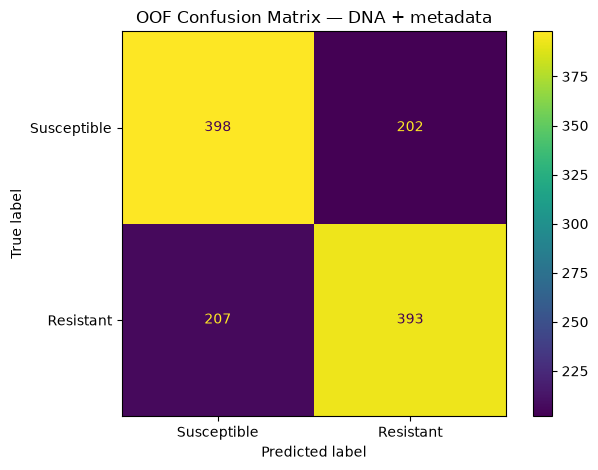

In [12]:
y_true = oof_predictions["actual"].astype(int)
y_pred = oof_predictions["predicted"].astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
print("Confusion matrix (rows = actual [susceptible, resistant], columns = predicted [susceptible, resistant]):")
print(cm)
print("\\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Susceptible", "Resistant"],
    digits=3,
    zero_division=0,
))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Susceptible", "Resistant"])
disp.plot(values_format="d")
plt.title(f"OOF Confusion Matrix — {combined_name}")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "notebook_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()


## 8. Evaluate organism–antibiotic combinations

,organism_group,antibiotic,rows,accuracy,balanced_accuracy,macro_f1,errors
5,Salmonella enterica,tetracycline,200,0.745,0.745,0.742678,51
1,Campylobacter jejuni,tetracycline,200,0.730,0.730,0.729973,54
4,Salmonella enterica,ampicillin,200,0.720,0.720,0.719551,56
3,E.coli and Shigella,tetracycline,200,0.625,0.625,0.624991,75
2,E.coli and Shigella,ampicillin,200,0.575,0.575,0.573710,85
0,Campylobacter jejuni,ciprofloxacin,200,0.560,0.560,0.559956,88


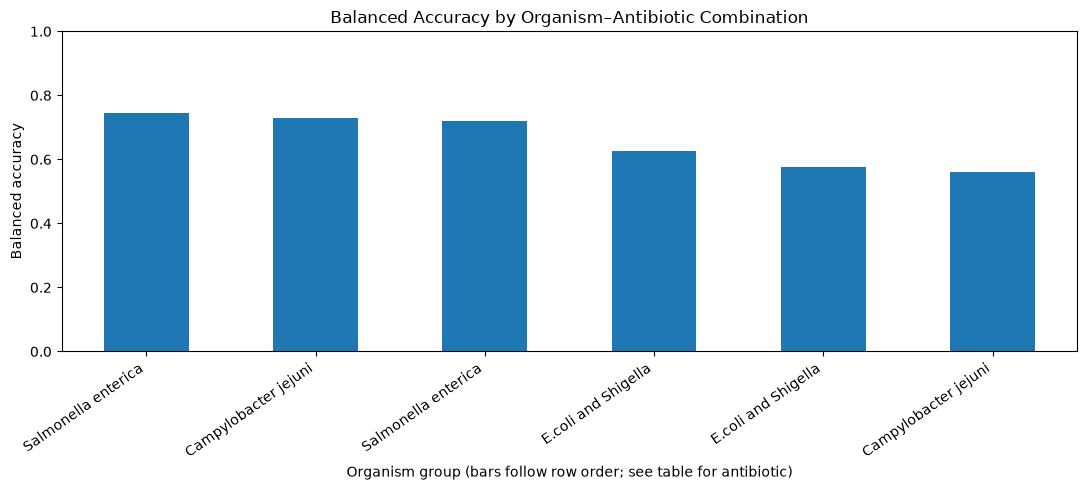

In [13]:
if {"organism_group", "antibiotic"}.issubset(oof_predictions.columns):
    combo_rows = []
    for (organism, antibiotic), part in oof_predictions.groupby(["organism_group", "antibiotic"]):
        combo_rows.append({
            "organism_group": organism,
            "antibiotic": antibiotic,
            "rows": len(part),
            "accuracy": accuracy_score(part["actual"], part["predicted"]),
            "balanced_accuracy": balanced_accuracy_score(part["actual"], part["predicted"]),
            "macro_f1": f1_score(part["actual"], part["predicted"], average="macro"),
            "errors": int((part["actual"] != part["predicted"]).sum()),
        })
    combo_results = pd.DataFrame(combo_rows).sort_values("balanced_accuracy", ascending=False)
    display(combo_results)
    combo_results.to_csv(RESULTS_DIR / "notebook_combination_results.csv", index=False)

    ax = combo_results.plot(
        x="organism_group", y="balanced_accuracy", kind="bar",
        legend=False, figsize=(11, 5), ylim=(0, 1),
    )
    ax.set_ylabel("Balanced accuracy")
    ax.set_xlabel("Organism group (bars follow row order; see table for antibiotic)")
    ax.set_title("Balanced Accuracy by Organism–Antibiotic Combination")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(CHARTS_DIR / "notebook_combination_performance.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("Combination analysis requires organism_group and antibiotic columns.")


## 9. False positives and false negatives

In [14]:
# Positive class = resistant (1)
# False positive (FP): actual susceptible (0), predicted resistant (1)
# False negative (FN): actual resistant (1), predicted susceptible (0)

fp = oof_predictions[(oof_predictions["actual"] == 0) & (oof_predictions["predicted"] == 1)].copy()
fn = oof_predictions[(oof_predictions["actual"] == 1) & (oof_predictions["predicted"] == 0)].copy()

print("False positives:", len(fp))
display(fp.head(10))
print("False negatives:", len(fn))
display(fn.head(10))

fp.to_csv(RESULTS_DIR / "notebook_false_positives.csv", index=False)
fn.to_csv(RESULTS_DIR / "notebook_false_negatives.csv", index=False)

if {"organism_group", "antibiotic"}.issubset(oof_predictions.columns):
    error_summary = (
        oof_predictions.assign(
            error_type=np.select(
                [
                    (oof_predictions["actual"] == 0) & (oof_predictions["predicted"] == 1),
                    (oof_predictions["actual"] == 1) & (oof_predictions["predicted"] == 0),
                ],
                ["False positive", "False negative"],
                default="Correct",
            )
        )
        .groupby(["organism_group", "antibiotic", "error_type"])
        .size().unstack(fill_value=0).reset_index()
    )
    display(error_summary)
    error_summary.to_csv(RESULTS_DIR / "notebook_misclassification_summary.csv", index=False)


False positives: 202


,row_index,actual,predicted,model,organism_group,antibiotic,biosample_accession
102,102,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN07633749
104,104,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN04600089
105,105,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN62387533
106,106,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN09605248
108,108,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN05505582
109,109,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN05505588
111,111,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN09783388
113,113,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN07633667
118,118,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN07633639
119,119,0,1,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN04508228


False negatives: 207


,row_index,actual,predicted,model,organism_group,antibiotic,biosample_accession
1,1,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN12035700
2,2,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN07633319
3,3,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN11047786
4,4,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN04599777
8,8,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN09605295
9,9,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN05440727
11,11,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN04599785
12,12,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN07633623
14,14,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN11047958
15,15,1,0,DNA + metadata,Campylobacter jejuni,ciprofloxacin,SAMN12585639


error_type,organism_group,antibiotic,Correct,False negative,False positive
0,Campylobacter jejuni,ciprofloxacin,112,45,43
1,Campylobacter jejuni,tetracycline,146,28,26
2,E.coli and Shigella,ampicillin,115,37,48
3,E.coli and Shigella,tetracycline,125,38,37
4,Salmonella enterica,ampicillin,144,24,32
5,Salmonella enterica,tetracycline,149,35,16


## 10. Train and save a final model

This trains a combined DNA + metadata model on the complete prepared dataset and saves it for later inference. The model is trained on all rows, so use the cross-validation results above—not training-set scores—to estimate generalization performance.

In [15]:
final_features = feature_sets.get("DNA + metadata", list(feature_sets.values())[-1])
final_model = make_pipeline(
    [c for c in final_features if c in categorical_cols],
    [c for c in final_features if c not in categorical_cols],
)
final_model.fit(df[final_features], y)

import joblib
final_model_path = MODELS_DIR / "notebook_random_forest_amr_model.joblib"
joblib.dump(final_model, final_model_path)
print("Saved model:", final_model_path)
print("Features used:", len(final_features))


Saved model: d:\MSC_AI\Pattern_Recognition_And_Machine_Learning\Project2_AMR\models\notebook_random_forest_amr_model.joblib
Features used: 258


## 11. Feature importance for DNA 4-mers

This extracts Random Forest feature importance from the fitted combined model and saves the top 20 DNA 4-mers. Importance indicates predictive association in this dataset; it does not prove that a particular 4-mer causes antibiotic resistance.

,transformed_feature,importance,feature
138,numeric__GACA,0.011820,GACA
171,numeric__GGCC,0.010057,GGCC
231,numeric__TGAC,0.008933,TGAC
120,numeric__CTAG,0.008685,CTAG
159,numeric__GCGC,0.008550,GCGC
243,numeric__TGTC,0.008414,TGTC
84,numeric__CATG,0.007956,CATG
45,numeric__AGCT,0.007843,AGCT
66,numeric__ATTA,0.007620,ATTA
132,numeric__CTTG,0.007572,CTTG


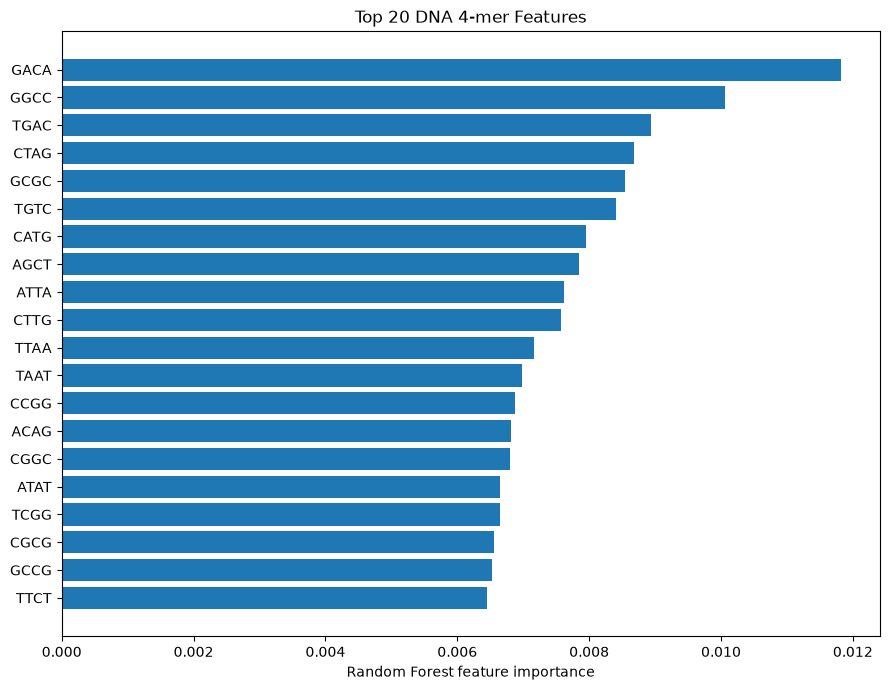

In [16]:
if dna_cols and "DNA + metadata" in feature_sets:
    fitted_preprocessor = final_model.named_steps["preprocess"]
    fitted_forest = final_model.named_steps["classifier"]
    transformed_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_forest.feature_importances_

    importance_df = pd.DataFrame({
        "transformed_feature": transformed_names,
        "importance": importances,
    })

    # The ColumnTransformer names numeric DNA columns like numeric__AAAA.
    importance_df["feature"] = importance_df["transformed_feature"].str.split("__", n=1).str[-1]
    kmer_importance = importance_df[importance_df["feature"].isin(dna_cols)].copy()
    kmer_importance = kmer_importance.sort_values("importance", ascending=False)

    display(kmer_importance.head(20))
    kmer_importance.to_csv(CHARTS_DIR / "notebook_all_kmer_importances.csv", index=False)
    top20 = kmer_importance.head(20).sort_values("importance")
    if not top20.empty:
        plt.figure(figsize=(9, 7))
        plt.barh(top20["feature"], top20["importance"])
        plt.xlabel("Random Forest feature importance")
        plt.title("Top 20 DNA 4-mer Features")
        plt.tight_layout()
        plt.savefig(CHARTS_DIR / "notebook_top20_kmer_importance.png", dpi=200, bbox_inches="tight")
        plt.show()
else:
    print("DNA 4-mer feature importance requires a combined model and detected 4-mer columns.")


## 12. Optional: extract 4-mer frequencies from FASTA files

Skip this section if `genome_4mer_features.csv` and `model_dataset.csv` already exist. It is provided to document the core feature-engineering method, but the original project’s exact file-discovery and phenotype-selection scripts may include additional project-specific handling.

The function below processes a single FASTA file. It ignores FASTA headers and non-ACGT characters, counts overlapping 4-mers, and normalizes counts by the number of valid windows.

In [17]:
from collections import Counter

DNA_ALPHABET = set("ACGT")
ALL_4MERS = ["".join(chars) for chars in itertools.product("ACGT", repeat=4)]

def fasta_sequence(path):
    parts = []
    with open(path, "r", encoding="utf-8", errors="ignore") as handle:
        for line in handle:
            line = line.strip()
            if not line or line.startswith(">"):
                continue
            parts.append(line.upper())
    return "".join(parts)

def compute_4mer_features(sequence):
    # Keep only valid DNA bases; ambiguous bases are removed.
    # Windows are counted on the cleaned sequence.
    sequence = "".join(base for base in sequence.upper() if base in DNA_ALPHABET)
    counts = Counter(
        sequence[i:i+4]
        for i in range(max(0, len(sequence) - 3))
    )
    total = sum(counts.values())
    features = {
        kmer: (counts.get(kmer, 0) / total if total else 0.0)
        for kmer in ALL_4MERS
    }
    features["valid_4mer_windows"] = total
    return features

# Example (small synthetic sequence; replace with a real FASTA path to test):
example = compute_4mer_features("ATGCATGC")
print("Example valid windows:", example["valid_4mer_windows"])
print({k: v for k, v in example.items() if len(k) == 4 and v > 0})


Example valid windows: 5
{'ATGC': 0.4, 'CATG': 0.2, 'GCAT': 0.2, 'TGCA': 0.2}


## 13. Outputs produced

The notebook writes its outputs under `Project2_AMR/project2_data/`:
- `results/notebook_holdout_model_comparison.csv`
- `results/notebook_cross_validation_folds.csv`
- `results/notebook_cross_validation_summary.csv`
- `results/notebook_combination_results.csv`
- `results/notebook_false_positives.csv`
- `results/notebook_false_negatives.csv`
- `results/notebook_misclassification_summary.csv`
- `charts/notebook_out_of_fold_predictions.csv`
- `charts/notebook_confusion_matrix.png`
- `charts/notebook_combination_performance.png`
- `charts/notebook_all_kmer_importances.csv`
- `charts/notebook_top20_kmer_importance.png`
- `models/notebook_random_forest_amr_model.joblib`

### Notes
- The notebook is a consolidated, reproducible modelling/analysis version based on the known project workflow and output structure.
- It does not claim to be a line-for-line conversion of every original `.py` file. To preserve every original implementation detail, the source scripts would need to be available for direct conversion.
- The genome feature extraction step may take significant time for the full collection of genomes.

In [ ]:
df.head()


,organism_group,biosample_accession,assembly_accession,antibiotic,ast_status_original,label,label_binary,strain,AAAA,AAAC,...,TTCT,TTGA,TTGC,TTGG,TTGT,TTTA,TTTC,TTTG,TTTT,valid_4mer_windows
0,Campylobacter jejuni,SAMN07633435,GCA_004972925.1,ciprofloxacin,R,resistant,1.0,CVM N16C119,0.032208,0.007852,...,0.008427,0.006886,0.006236,0.003698,0.005575,0.019825,0.008975,0.010838,0.031017,1691887
1,Campylobacter jejuni,SAMN12035700,GCA_006358955.1,ciprofloxacin,R,resistant,1.0,CVM N18C559,0.032185,0.007560,...,0.008234,0.007079,0.006188,0.003892,0.005761,0.019904,0.008679,0.011103,0.030959,1734795
2,Campylobacter jejuni,SAMN07633319,GCA_004971725.1,ciprofloxacin,R,resistant,1.0,CVM N16C001,0.031665,0.007219,...,0.008386,0.007234,0.006265,0.004033,0.005970,0.020137,0.008739,0.011558,0.031596,1684777
3,Campylobacter jejuni,SAMN11047786,GCA_005119285.1,ciprofloxacin,R,resistant,1.0,CVM N18C257,0.030761,0.006788,...,0.007880,0.007332,0.006303,0.004069,0.005843,0.019121,0.008333,0.011446,0.029808,1815241
4,Campylobacter jejuni,SAMN04599777,GCA_005287165.1,ciprofloxacin,R,resistant,1.0,FSIS1606038,0.030849,0.006816,...,0.007737,0.007364,0.006443,0.004081,0.005558,0.019221,0.008299,0.011429,0.030062,1684710
